# 06 — The Graph Model (final, public LB 0.960)

**Where we are.** After notebook 05 the best model was LightGBM on the 165 raw features (public LB **0.948**).
Notebook 04 concluded that graph features "gave no reliable gain". This notebook explains why we went back to the
graph anyway, what was different the second time, and how we reached the final model.

The path, in one line each:

1. **Re-check our validation** against the leaderboard results we already have, and pick the split that agrees with it.
2. **Re-read an EDA finding** (notebook 01): the test set is exactly the originally-*labelled* transactions of steps
   36–49. This makes some graph features mean the same thing in train and test.
3. **Measure homophily:** illicit transactions are linked to other illicit transactions far more than chance.
4. Turn that into features in a way that does not leak labels (**neighbour scores**, not neighbour features).
5. **Weight recent time steps more** (recency weighting).
6. Record what was tried and dropped, refit on steps 1–35, and confirm the result on the leaderboard.

The model code lives in `src/graph2.py` (features) and `src/make_submission.py` (the two-stage model). This notebook
calls those functions directly, so the numbers here come from the same code as the submitted file.

*Runtime: about 10–15 minutes.*

In [1]:
import sys, warnings
from datetime import date
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

from src.data import load_train, load_test, load_edges, labeled, FEATURE_COLS, LABEL_COL, ID_COL, TIME_COL, SUBMISSIONS_DIR
from src.graph2 import known_ids, known_edges, structural_features, neighbour_score_features
from src.make_submission import stage1, fit_predict, predict
from src.validation import log_experiment

TODAY, NOTEBOOK = date.today().isoformat(), "06_graph_model"
EASY_ENDS = [24, 26, 28, 30]   # main check: fit windows that include step 23
HARD_ENDS = [20, 22]           # sanity check: fit windows that end before step 23
SEEDS = (42, 1, 2)             # every validation score is a 3-seed average

C_A, C_B, C_MUTED = "#2a78d6", "#eb6834", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.edgecolor": C_MUTED, "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "legend.frameon": False,
})

train, test, edges = load_train(), load_test(), load_edges()
L = labeled(train)

## 1. Which validation split agrees with the leaderboard?

By now three submissions have leaderboard scores. Notebooks 04–05 judged models on two splits: the *standard* split
(fit 1–24) and the *hard* split (fit 1–22, which hides the step-23 pattern). If a split is a good guide, it should
rank these three submissions in the same order as the leaderboard.

In [2]:
log = pd.read_csv(ROOT / "experiments.csv")
pick = lambda nb, change: log[(log.notebook == nb) & (log.change == change)].iloc[0]
rows = [
    ("Random Forest (03)", pick("03_baseline_models", "Baseline Random Forest, raw 165 features, class_weight=balanced").val_auc,
     0.8091, pick("03_baseline_models", "SUBMISSION Random Forest class_weight=balanced, refit on steps 1-35").public_lb_auc),
    ("LightGBM, 165 raw (04)", pick("04_graph_features", "SUBMISSION lgbm_raw, refit on steps 1-35").val_auc, 0.8751,
     pick("04_graph_features", "SUBMISSION lgbm_raw, refit on steps 1-35").public_lb_auc),
    ("Blend with feat_94-165 model (04)", pick("04_graph_features", "SUBMISSION blend_raw_f94, refit on steps 1-35").val_auc,
     0.9141, pick("04_graph_features", "SUBMISSION blend_raw_f94, refit on steps 1-35").public_lb_auc),
]
proxy = pd.DataFrame(rows, columns=["submission", "standard split", "hard split", "public LB"]).set_index("submission")
for col in proxy:
    proxy[f"rank: {col}"] = proxy[col].rank(ascending=False).astype(int)
proxy.round(4)

,standard split,hard split,public LB,rank: standard split,rank: hard split,rank: public LB
submission,,,,,,
Random Forest (03),0.9965,0.8091,0.9336,2,3,2
"LightGBM, 165 raw (04)",0.9971,0.8751,0.9483,1,2,1
Blend with feat_94-165 model (04),0.9906,0.9141,0.9200,3,1,3


*(The hard-split AUCs are the values notebook 04 logged in the `notes` column of `experiments.csv`.)*

**The standard split ranks the three submissions exactly like the leaderboard; the hard split does not.** It ranks
the blend first, but the blend did worst on the leaderboard. The hard split was built to imitate "illicit patterns
the model has never seen", but in practice it rewarded the wrong submission.

So from here on:

- **Main check ("easy"):** the *average* pooled AUC over four fit windows that include step 23 (fit 1–24, 1–26,
  1–28, 1–30, each validated on the following steps up to 35). Averaging four windows makes it steadier than one split.
- **Sanity check ("hard"):** the average over fit 1–20 and 1–22. We don't choose by it, but a change that badly hurts
  it is suspicious.
- Every score is averaged over 3 seeds, because notebook 04 found seed noise of about 0.005–0.009 on a single split.

Tree models already score about 0.998 on the main check, so real improvements will look small, around +0.0005.

## 2. Back to the graph: what the test set is made of

Notebook 01 found that `train` labelled rows (31,235) + `test` rows (15,329) = the 46,564 labelled transactions of
the original Elliptic data. The 46,668 transactions that appear only in the edge list are the **unlabelled**
transactions of steps 36–49.

Notebook 04 treated this as a *problem*: test transactions cannot "see" those neighbours. But it is also an
*opportunity*. For every transaction, we can tell whether each neighbour is labelled or not, and this means the same
thing in train and test:

| | Labelled neighbour | Unlabelled neighbour |
|---|---|---|
| Train steps 1–35 | row in `train` with a label | row in `train` with no label |
| Test steps 36–49 | row in `test` | edge-list-only node |

So we can count, for each transaction, how many neighbours are labelled and how many are not. Those counts are the
**structural features** (`structural_features` in `src/graph2.py`):

- `indeg` / `outdeg`: number of incoming / outgoing edges (on the full edge list, as in notebook 04);
- `in_known` / `out_known`: how many of those connect to a labelled transaction;
- `in_unk` / `out_unk`: how many connect to an unlabelled one;
- `frac_known`: the share of all neighbours that are labelled.

How informative is each one on its own? (AUC on all labelled training rows; 0.5 = no signal.)

In [3]:
known = known_ids(train, test)
kedges = known_edges(edges, known)
S = structural_features(edges, pd.concat([L[ID_COL], test[ID_COL]]), known)
STRUCT = list(S.columns)
data = L.join(S, on=ID_COL)

single = pd.Series({c: roc_auc_score(data[LABEL_COL], data[c]) for c in STRUCT}, name="AUC alone")
pd.DataFrame({"AUC alone": single, "signal strength (|AUC - 0.5| + 0.5)": (single - 0.5).abs() + 0.5}).round(3)

,AUC alone,signal strength (|AUC - 0.5| + 0.5)
indeg,0.458,0.542
outdeg,0.417,0.583
in_known,0.387,0.613
out_known,0.387,0.613
in_unk,0.555,0.555
out_unk,0.516,0.516
frac_known,0.387,0.613


Each count is a weak signal on its own (about 0.52–0.61), similar to plain degree in notebook 04. Illicit
transactions tend to have **fewer labelled neighbours**. One caveat for the report: this signal partly reflects
how the dataset was built (which transactions got labelled), not just criminal behaviour, so it would not carry over
to a real deployment where nothing is labelled yet.

## 3. Homophily: illicit transactions link to illicit transactions

For every edge whose two ends are both labelled training transactions, we look at both ends: if one end is illicit,
how often is the other end illicit too?

In [4]:
lab = L.set_index(ID_COL)[LABEL_COL]
e = edges.assign(a=edges.txId1.map(lab), b=edges.txId2.map(lab)).dropna(subset=["a", "b"])
pairs = pd.concat([e[["a", "b"]], e[["b", "a"]].set_axis(["a", "b"], axis=1)])   # look from both ends
homophily = pairs.groupby("a").b.agg(["size", "mean"]).rename(
    index={0.0: "licit", 1.0: "illicit"}, columns={"size": "edge ends", "mean": "share of neighbours illicit"})
base_rate = L[LABEL_COL].mean()
print(f"labelled edges: {len(e):,}   |   overall illicit rate among labelled rows: {base_rate:.1%}")
homophily.round(3)

labelled edges: 23,900   |   overall illicit rate among labelled rows: 11.7%


,edge ends,share of neighbours illicit
a,,
licit,44815,0.028
illicit,2985,0.574


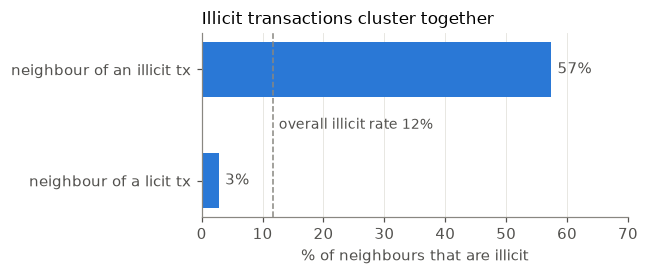

In [5]:
fig, ax = plt.subplots(figsize=(6, 2.6))
vals = homophily["share of neighbours illicit"] * 100
bars = ax.barh(["neighbour of a licit tx", "neighbour of an illicit tx"], vals[["licit", "illicit"]], color=C_A, height=0.5)
ax.axvline(base_rate * 100, color=C_MUTED, lw=1, ls="--")
ax.text(base_rate * 100 + 1, 0.5, f"overall illicit rate {base_rate:.0%}", va="center", color="#52514e", fontsize=9)
for b, v in zip(bars, vals[["licit", "illicit"]]):
    ax.text(v + 1, b.get_y() + b.get_height() / 2, f"{v:.0f}%", va="center", color="#52514e", fontsize=10)
ax.set_xlim(0, 70); ax.set_xlabel("% of neighbours that are illicit")
ax.set_title("Illicit transactions cluster together", loc="left", fontsize=11)
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**This is the strongest graph signal we have found.** 57% of the labelled neighbours of an illicit transaction are
illicit, against about 3% for a licit one (and 11.7% overall). This fits the "peeling chain" picture from notebook 01: illicit money
moves through chains of linked transactions.

Edges never cross time steps (notebook 01), so a test transaction's neighbours are all in the test period, with no
labels. We cannot use neighbours' *labels*. The question is how to use neighbours' *suspiciousness* instead.

## 4. Neighbour scores, not neighbour features

Notebook 04 already tried averaging the neighbours' **165 features**, and it did not help. Here we average the
neighbours' **predicted probability of being illicit** instead. Why should that work better?

- The 165 features mostly describe the transaction's own neighbourhood already (the last ~72 are neighbour
  aggregates in the original data), so averaging them again adds little.
- A model score squeezes the 165 features into **one number that is about illicitness**. Given the homophily above,
  "my neighbours look illicit" is exactly the clue we want, and one number is much easier for the final model to use
  than 165 averaged columns.

**The model, in two stages** (`stage1` and `predict` in `src/make_submission.py`):

1. **Stage 1:** LightGBM on raw + structural features gives every labelled transaction a score.
2. For each transaction, take the **mean and max** of its labelled neighbours' stage-1 scores. This is done separately
   for incoming, outgoing and all neighbours (`neighbour_score_features` in `src/graph2.py`), giving 6 columns.
3. **Stage 2:** the final LightGBM uses raw + structural + neighbour-score features.

**Avoiding leakage.** If a training row were scored by a stage-1 model that had learned from that same row (or from
its neighbours in the same step), its score would be too good, and stage 2 would learn to trust neighbour scores more
than it should. So training rows get **out-of-fold** scores: the fit steps are cut into 5 blocks of consecutive time
steps, and each block is scored by a model trained on the other four. Edges never cross time steps, so a row and all
its neighbours are always scored by a model that saw none of them. Validation and test rows are scored by a stage-1
model trained on all fit rows, which is exactly what will happen at test time.

The next cell builds stage 1 once for each of the six validation fit windows (about 2 minutes).

In [6]:
splits = {}
for end in HARD_ENDS + EASY_ENDS:
    fit, val = data[data[TIME_COL] <= end], data[data[TIME_COL] > end]
    N = neighbour_score_features(kedges, stage1(fit, val, FEATURE_COLS + STRUCT))
    splits[end] = (fit.join(N, on=ID_COL), val.join(N, on=ID_COL))
NB = list(N.columns)
print("neighbour-score features:", NB)

FEATURE_SETS = {"raw": FEATURE_COLS, "raw + struct": FEATURE_COLS + STRUCT, "raw + struct + nb": FEATURE_COLS + STRUCT + NB}


def score(features, decay=None, params=None):
    '''Pooled AUC on each fit window (3-seed average), then the easy and hard means.'''
    feats = FEATURE_SETS[features]
    out = {}
    for end, (fit, val) in splits.items():
        w = None if decay is None else decay ** (end - fit[TIME_COL].values)
        p = fit_predict("lgb", fit[feats], fit[LABEL_COL], val[feats], seeds=SEEDS, w=w, params=params)
        out[f"1-{end}"] = roc_auc_score(val[LABEL_COL], p)
    r = pd.Series(out)
    return {"easy": r[[f"1-{e}" for e in EASY_ENDS]].mean(), "hard": r[[f"1-{e}" for e in HARD_ENDS]].mean(), **out}

neighbour-score features: ['nb_in_mean', 'nb_in_max', 'nb_out_mean', 'nb_out_max', 'nb_all_mean', 'nb_all_max']


## 5. Recency weighting

Illicit behaviour drifts over time (notebook 04's step-23 pattern is one example), and the test steps come
straight after step 35. **Recency weighting** makes older training rows count less: a row from *k* steps before the
end of the fit window gets weight 0.95<sup>*k*</sup>. With decay 0.95 the latest step counts 1.0, a step 10 steps
earlier 0.60, and step 1 of the full 1–35 fit about 0.17. Old data still helps, but recent data leads. Smaller decay
values (0.9, 0.85) forget faster.

`time_step` is only used to set these training weights. It is still never a model input, so the rule from
notebook 02 holds: test rows are scored from their features alone.

## 6. Building the model one step at a time

Each row adds one thing to the row above it, so we can see what each step contributes.

In [7]:
ladder = {
    "LightGBM, 165 raw (LB 0.948)": score("raw"),
    "+ structural features": score("raw + struct"),
    "+ neighbour scores": score("raw + struct + nb"),
    "+ recency weighting 0.95": score("raw + struct + nb", decay=0.95),
}
ladder = pd.DataFrame(ladder).T
ladder["easy vs previous"] = ladder.easy.diff()
ladder["hard vs previous"] = ladder.hard.diff()
ladder.round(4)

,easy,hard,1-20,1-22,1-24,1-26,1-28,1-30,easy vs previous,hard vs previous
"LightGBM, 165 raw (LB 0.948)",0.9976,0.8927,0.9066,0.8788,0.9972,0.9975,0.9972,0.9985,NaN,NaN
+ structural features,0.9978,0.8874,0.9072,0.8675,0.9973,0.9977,0.9975,0.9985,0.0002,-0.0053
+ neighbour scores,0.9982,0.8865,0.9017,0.8713,0.9977,0.9982,0.9983,0.9986,0.0005,-0.0009
+ recency weighting 0.95,0.9984,0.8925,0.9088,0.8763,0.9979,0.9985,0.9985,0.9986,0.0001,0.0060


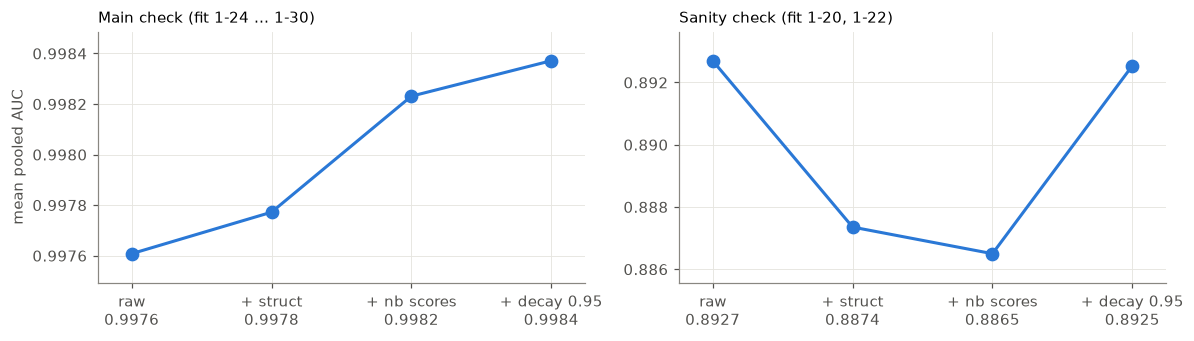

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
labels = ["raw", "+ struct", "+ nb scores", "+ decay 0.95"]
for ax, col, title in [(axes[0], "easy", "Main check (fit 1-24 ... 1-30)"), (axes[1], "hard", "Sanity check (fit 1-20, 1-22)")]:
    ax.plot(range(4), ladder[col].values, color=C_A, lw=2, marker="o", ms=8)
    ax.set_xticks(range(4), [f"{l}\n{y:.4f}" for l, y in zip(labels, ladder[col].values)])   # value under each step
    ax.set_title(title, loc="left", fontsize=10)
    ax.margins(x=0.08, y=0.15)
axes[0].set_ylabel("mean pooled AUC")
plt.tight_layout(); plt.show()

**Reading the ladder** (the two panels have different y-ranges, so compare the shape within each, not the heights):

- **Structural features alone** barely move the main check (+0.0002) and hurt the sanity check (-0.005). Alone they
  are not enough, which matches notebook 04's finding for degree.
- **Neighbour scores** give the largest step on the main check (+0.0005), with a small further loss on the sanity check.
- **Recency weighting** improves *both* checks, and wins back the sanity-check loss of the two graph steps.
- **Overall**, the final model gains +0.0008 on the main check and ties the raw model on the sanity check
  (0.8925 vs 0.8927). Gains of this size are close to what validation can detect, so the leaderboard was the real
  test: 0.948 → 0.960 (section 9).

Next: is 0.95 the right strength?

In [9]:
decays = pd.DataFrame({f"decay {d}": score("raw + struct + nb", decay=d) for d in [0.95, 0.9, 0.85]}).T
decays.round(4)

,easy,hard,1-20,1-22,1-24,1-26,1-28,1-30
decay 0.95,0.9984,0.8925,0.9088,0.8763,0.9979,0.9985,0.9985,0.9986
decay 0.9,0.9985,0.8903,0.9105,0.8701,0.9981,0.9986,0.9985,0.9987
decay 0.85,0.9985,0.8883,0.9058,0.8708,0.9982,0.9985,0.9986,0.9986


Stronger weighting (0.9, 0.85) ties 0.95 on the main check (differences of about 0.0001) and is a little worse on the
sanity check, because forgetting faster leaves fewer illicit examples to learn from. **We keep 0.95.**

In [10]:
for name, r in ladder.iterrows():
    log_experiment(TODAY, NOTEBOOK, f"Ladder: {name}", val_auc=r.easy,
                   notes=f"easy = mean of fit 1-24/26/28/30; hard (fit 1-20/22) {r.hard:.4f}; 3 seeds")
for name, r in decays.iterrows():
    log_experiment(TODAY, NOTEBOOK, f"Graph model, {name}", val_auc=r.easy, notes=f"hard {r.hard:.4f}; 3 seeds")

## 7. Ideas tried and dropped

These were tested with the same splits (scripts in `scripts/`, scores in `experiments.csv`). Each adds one thing to
the final model (graph features + recency weighting 0.95), except the rows marked "no decay".

| Idea | Main check | Sanity check | Verdict |
|---|---|---|---|
| **Final model** | **0.9984** | **0.893** | kept (LB 0.960) |
| Second round of neighbour scores, no decay | 0.9981 | 0.888 | dropped: no gain |
| Two-hop neighbour scores, no decay | 0.9980 | 0.871 | dropped: hurts sanity check |
| Blend with ExtraTrees, no decay | 0.9985 | 0.844 | dropped: big loss on sanity check |
| Blend with Random Forest, no decay | 0.9977 | 0.857 | dropped: worse on both |
| Post-hoc neighbour smoothing, weight 0.1 | 0.9976 | 0.893 | dropped: worse on main check |
| Post-hoc neighbour smoothing, weight 0.3 | 0.9910 | 0.888 | dropped: much worse |
| 1000 trees | 0.9986 | 0.885 | dropped: trades one check for the other |
| 31 leaves, 60% of columns, min 100 per leaf | 0.9983 | 0.898 | tested on LB as a hedge: **0.957** |
| 7 leaves / 15% columns / subsampling / more regularisation | 0.9978–0.9984 | 0.873–0.890 | dropped |

**Post-hoc smoothing** (final score = weighted average of a transaction's own score and its neighbours' mean score)
is the simpler, more common way to use homophily. It hurts here because stage 2 already uses the neighbour scores
and *learns* how much to trust them. A fixed blend on top only adds noise.

**The 31-leaf model** was the closest alternative, so it was submitted as a check. It scored 0.957, slightly below
0.960, which is consistent with the validation tie: the two differ by about the noise of a 30% leaderboard sample.

## 8. Final model: refit on steps 1–35

The final model refits everything (stage 1 with out-of-fold scores, then stage 2 with 5 seeds and recency weighting
0.95) on all labelled rows of steps 1–35. Here we rebuild it with `predict()`, the same function the command line uses:

```bash
python -m src.make_submission 2026-10-23_lgb_graph_nb_decay95 --decay 0.95
```

and check that it reproduces the submitted file, instead of writing a new one.

In [11]:
p = predict(train, test, edges, decay=0.95)
submitted = pd.read_csv(SUBMISSIONS_DIR / "2026-10-23_lgb_graph_nb_decay95.csv")
assert (submitted["index"].values == test["index"].values).all()
print(f"max absolute difference vs submitted file: {np.abs(submitted.target.values - p).max():.2e}")
print(f"rank correlation vs submitted file: {pd.Series(p).corr(submitted.target, method='spearman'):.6f}")

max absolute difference vs submitted file: 1.11e-16
rank correlation vs submitted file: 1.000000


## 9. Leaderboard history

| Submission | Notebook | Public LB |
|---|---|---|
| Random Forest, 165 raw | 03 | 0.934 |
| LightGBM, 165 raw | 04 | 0.948 |
| Blend with feat_94–165 model | 04 | 0.920 |
| **+ recency weighting 0.95 (final)** | **06** | **0.960** |
| 31-leaf variant (hedge) | 06 | 0.957 |

## Summary

1. **Validation was re-checked against the leaderboard.** The standard split (fit windows that include step 23)
   ranks past submissions in the same order as the leaderboard; the hard split does not. We now choose by an average
   over four standard windows, with the hard split only as a sanity check.
2. **The test set's construction made graph features usable.** Test = the originally-labelled transactions of steps
   36–49, so "is my neighbour labelled?" means the same thing in train and test.
3. **Homophily is strong:** 57% of an illicit transaction's labelled neighbours are illicit, against about 3% for a
   licit one.
4. **Neighbour *scores* work where neighbour *features* did not** (notebook 04): a model score is one number about
   illicitness, and out-of-fold scoring by time-step blocks keeps it leak-free.
5. **Recency weighting (0.95)** is the only change that improved both validation checks; it offsets the small
   sanity-check cost of the graph features.
6. **Result: public LB 0.948 → 0.960.**

**Limitations.**

- All validation windows end at step 35, before the step-43 dark-market shutdown, so validation cannot measure how
  well any model copes with it. Gains on validation are now around +0.0005, close to what we can reliably detect.
- The public leaderboard uses only 30% of the test data, so differences of a few thousandths (0.960 vs 0.957) may
  not survive on the full test set. That is why the final choice was made by validation first.
- The structural features rely on how the dataset was labelled, which would not be available in a real deployment.